# ***Data Exploration***
After the initial step of data prepration we obtained a full dataset for corn yield in 2020. We want to analiza this data further so that a reliable machine learning model can be created based on this data. 


In [1]:
# initial imports
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

Firstly, we can learn about how many and what kind of features does the dataset provide. We can also get an idea of the data type that each of the features is represented by.

In [2]:
path = 'C:/Users/nikak/Desktop/szkola/ML_Cropet/data/full_dataset_corn_2020'
df = pd.read_csv(path)

display(df.describe(include='all'))

print(f"Number of samples: {len(df)}")
print(df.dtypes)

,fips,county,state,year,yield_bu_acre,jan_temp_mean_k,jan_temp_std_k,jan_temp_max_k,jan_temp_min_k,jan_precip_mean_mm,...,nov_ndvi_crop_mean,nov_ndvi_crop_per_km2,nov_cloud_area_km2,nov_cloud_per_km2,dec_area_km2,dec_crop_area_km2,dec_ndvi_crop_mean,dec_ndvi_crop_per_km2,dec_cloud_area_km2,dec_cloud_per_km2
count,1601.000000,1601,1601,1601.0,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,...,1601.000000,1601.000000,1601.0,1601.0,1601.000000,1601.000000,1569.000000,1601.000000,1601.0,1601.0
unique,NaN,1005,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,WASHINGTON,IL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,18,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,28905.316677,NaN,NaN,2020.0,154.926921,274.951898,4.905296,289.144264,260.746704,3.080043,...,0.228386,0.059447,0.0,0.0,1817.305689,463.476371,0.211611,0.041748,0.0,0.0
std,12436.152538,NaN,NaN,0.0,35.974390,5.992475,0.981472,6.623779,7.826905,1.820296,...,0.085110,0.045396,0.0,0.0,1187.466447,639.645724,0.093659,0.040078,0.0,0.0
min,1001.000000,NaN,NaN,2020.0,22.800000,261.097124,2.011532,272.139963,239.876552,0.092205,...,0.055290,0.000245,0.0,0.0,270.996331,0.000000,0.000000,0.000000,0.0,0.0
25%,19111.000000,NaN,NaN,2020.0,132.100000,271.356127,4.404308,285.665750,256.204294,1.751027,...,0.163308,0.017723,0.0,0.0,1129.125605,44.673441,0.145330,0.007850,0.0,0.0
50%,28033.000000,NaN,NaN,2020.0,161.300000,274.571112,4.886299,290.211917,261.888917,2.894735,...,0.204544,0.051672,0.0,0.0,1500.597744,207.916283,0.190594,0.030198,0.0,0.0
75%,39061.000000,NaN,NaN,2020.0,182.200000,279.151465,5.418277,293.723893,266.200000,4.047551,...,0.290974,0.096572,0.0,0.0,2086.834469,657.748352,0.282589,0.067490,0.0,0.0


Number of samples: 1601
fips                       int64
county                       str
state                        str
year                       int64
yield_bu_acre            float64
                          ...   
dec_crop_area_km2        float64
dec_ndvi_crop_mean       float64
dec_ndvi_crop_per_km2    float64
dec_cloud_area_km2         int64
dec_cloud_per_km2        float64
Length: 317, dtype: object


In the final dataset we have 1601 samples and 317 features and the ground truth crop yeild.

The features in the dataset can be divided into 4 parts:
1. the general information of the county: the counties FIPS code, county name, state that the county is in and the year,
2. the weather data features for each month of the year,
3. the Sentinel-2 derived features for each month of the year,
4. the ground truth yield lables obtained through the USDA dataset;

The features and their descriptions are presented in the table below:

Feature Name | Description 
----------------------------------- | -------------------------
`fips` |  Unique identifier of the county in question
`county` | County name
`state` | Abbreviation of State name
`year` | Year (in our case 2020)
`yield_bu_acre` | Yearly yield for the county in bushels per acre
`{month}_temp_mean_k` | Mean monthly temperature in Kelvin
`{month}_temp_std_k` | Monthly standard deviation of the temperature in Kelvin
`{month}_temp_max_k` | Maximum temperature recorded in a given month in Kelvin
`{month}_temp_min_k` | Minimum temperature recorded in a given month in Kelvin
`{month}_precip_mean_mm` | Mean precipitation for a given month in milimiters
`{month}_precip_std_mm` | Monthly standard deviation of precipitation in milimiters
`{month}_rh_mean_pct` | Monthly mean relative humidity in %
`{month}_rh_std_pct` | Monthly standard deviation in relative humidity in %
`{month}_gust_mean_m_s` | Monthly mean gust speed in m/s
`{month}_gust_std_m_s` | Montlhy standard deviation of gust speed in m/s
`{month}_wind_mean_m_s` | Monthly average of the wind speed in a given county in m/s
`{month}_wind_std_m_s` | Standard deviation of the wind seed in a given month in m/s
`{month}_wind_u_mean_m_s` | Mean horizontal wind speed moving towards the East in m/s 
`{month}_wind_u_std_m_s` | Standard deviation of the horizontal wind speed moving towards the East in m/s 
`{month}_wind_v_mean_m_s`| Mean horizontal wind speed moving towards the North in m/s 
`{month}_wind_v_std_m_s`| Standard deviation of the horizontal wind speed moving towards the North in m/s 
`{month}_srad_mean_w_m2`| Monthly mean shortwave radiation the reaches the Earth in W/m2
`{month}_srad_std_w_m2`| Standard deviation of the shortwave radiation the reaches the Earth in W/m2
`{month}_vpd_mean_kpa`| 
`{month}_vpd_std_kpa` | 
`{month}_area_km2` | Total county area covered, km² 
`{month}_crop_area_km2`  | Area classified as cropland in that month, km² 
`{month}_mean_crop_ndvi` | Mean NDVI over cropland pixels (NaN when crop area is 0) 
`{month}_crop_ndvi_per_km2` | `mean_crop_ndvi × crop_area_km2 / area_km2`, i.e. crop NDVI weighted by crop share of the county 
`{month}_cloud_area_km2` | Cloud-covered area, km² 
`{month}_cloud_per_km2` | `cloud_area_km2 / area_km2`, i.e. cloud fraction 

With the code in the cell above we checked that most of the features are numerical and only descriptive features like the county name or state abbriveation are of type string. We can then set our target column to `"yield_bu_acre"` and define the descrptive columns.


In [3]:
target_label = "yield_bu_acre"
# even though fips and year have a numerical data type they are not going to be considered as numerical variables in our analysis 
non_numeric_labels = ["fips", "county", "state", "year"]

The next step would be to check if there are any no-data values in our dataset. 

## **Handeling of Missing values**

In [4]:
# explore the data in regards to no-data values 
missing_values_col_list = []
for col in df.columns:
    sum_nan = df[col].isna().sum()
    if sum_nan != 0:
        print(f'{col}: {sum_nan}')
        missing_values_col_list.append(col)
print(missing_values_col_list)

jan_ndvi_crop_mean: 116
feb_ndvi_crop_mean: 61
mar_ndvi_crop_mean: 14
oct_ndvi_crop_mean: 2
dec_ndvi_crop_mean: 32
['jan_ndvi_crop_mean', 'feb_ndvi_crop_mean', 'mar_ndvi_crop_mean', 'oct_ndvi_crop_mean', 'dec_ndvi_crop_mean']


We can see that all of the no-data values fall in the '{month}_ndvi_crop_mean' variable. 

This fact comes from the definitio of this pertiular feature. The ndvi_crop_mean feature was calculated by dividing the sum of ndvi over the crop region by the crop area obtaied from Dynamic World (DW). 

The months in which the problem occures are Jnuary, February, March, October and December, which are especially cloudy in the northen hemisfere. They could be also considered as winter months when crop fields don't ocurre too often. 

For those resons the DW masks for thouse months might have either been cloudy or if in a perticular month in a perticular county the crop area was equal to 0 then the division was impossible and the value is set to nan. 

Because we could identify this problem and we know the porpuse of it we can fill the no-data values with 0 as there is no crop in this pertcular case. 

In [5]:
# filling the no-data values with 0
df = df.fillna(0)

## **Feature selection**

The next step is to select features that would provide valuable information that would explian the target variable.

Firstly, we look into cloud features to check their importance.

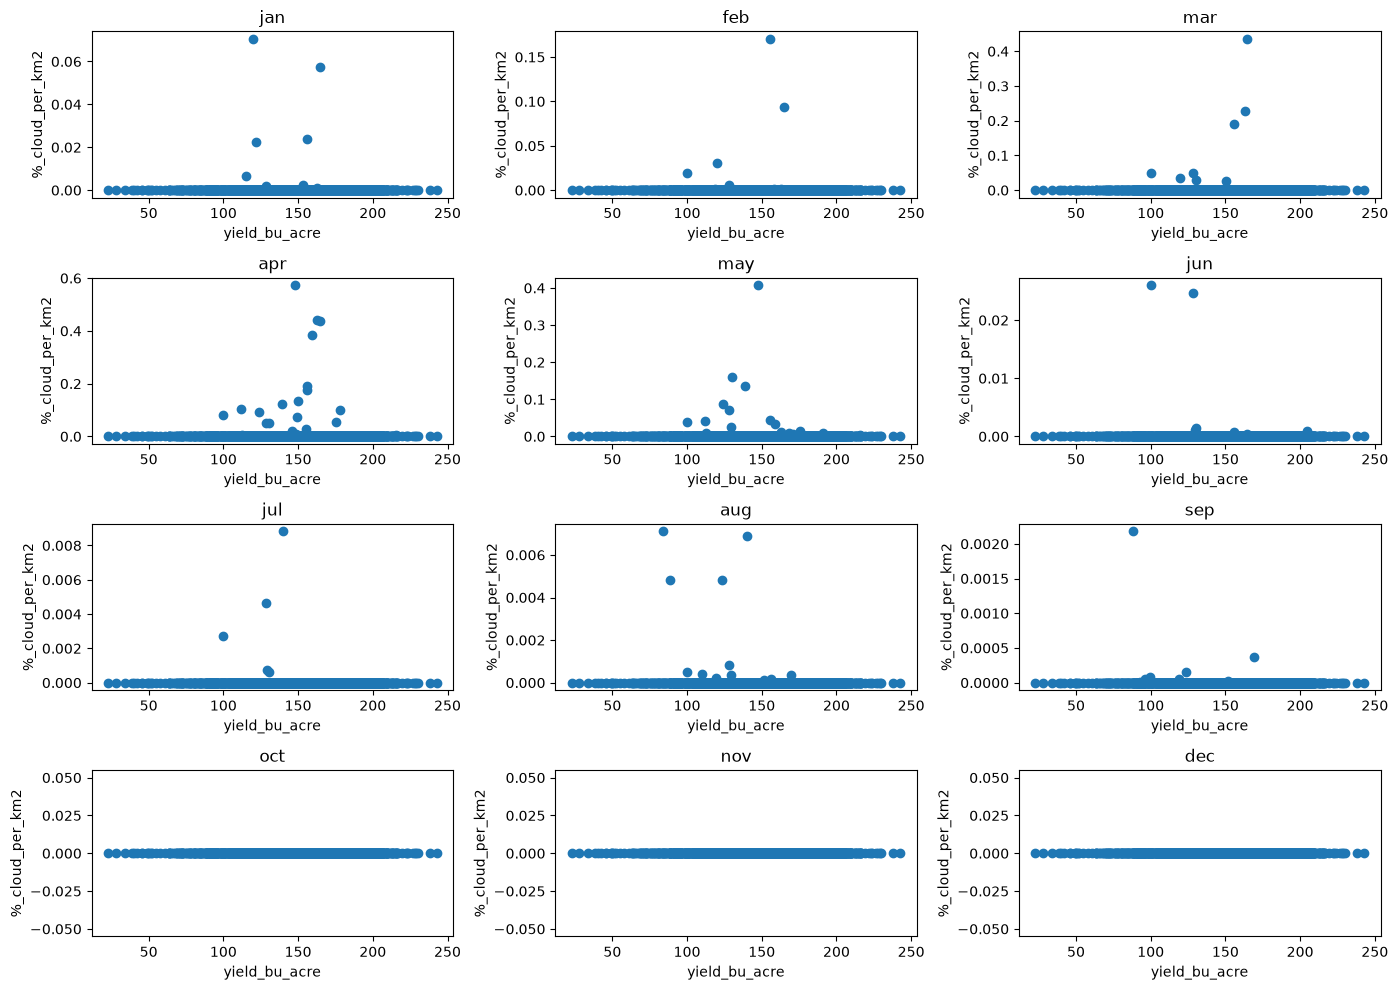

In [6]:
MONTHS = [
   'jan', 'feb', 'mar', 'apr',
   'may', 'jun', 'jul', 'aug',
   'sep', 'oct', 'nov', 'dec'
]

fig, axs = plt.subplots(4, 3, figsize=(14, 10))
for ax, m in zip(axs.flat, MONTHS):
    cloud_frac_column = f"{m}_cloud_per_km2"
    ax.set_title(f'{m}')
    ax.scatter(df[target_label], df[cloud_frac_column])
    ax.set_ylabel('%_cloud_per_km2')
    ax.set_xlabel('yield_bu_acre')
plt.tight_layout()
    
plt.show()

In [7]:
def remove_cloud_features(df):
   cloud_frac_columns = [f"{m}_cloud_per_km2" for m in MONTHS]
   total_gt_20 = (df[cloud_frac_columns] > 0.20).sum().sum()
   total_eq_0 = (df[cloud_frac_columns] < 0.001).sum().sum()

   print(f"Percentage Cloud Cover > 0.20: {total_gt_20/(len(df)*len(MONTHS)):.4f}")
   print(f"Percentage Cloud Cover < 0.001: {total_eq_0/(len(df)*len(MONTHS)):.4f}")
   print("Therefore, removing cloud features...")

   cloud_columns = cloud_frac_columns + [f"{m}_cloud_area_km2" for m in MONTHS]
   return df.drop(cloud_columns, axis=1)

df_selected_features = remove_cloud_features(df)

Percentage Cloud Cover > 0.20: 0.0004
Percentage Cloud Cover < 0.001: 0.9959
Therefore, removing cloud features...


We can see that the cloud cover in most of the cases (99.6%) is very very small and very similar between different months and samples. For this reason the clou cover features included in our dataset can be discarded as they don't act as good explainers of the behaviour of our target varaible. 

After the removal of the cloud features, which didn't provide much information, the amount of features per sample went down to **293** out of which 4 are the descriptive features like fips, state, year and county. 

Next, we have to look into the ndvi features as during the data exploration it turned out that because of the way that the data was acquired some months for some of the counties are not properly covered. 

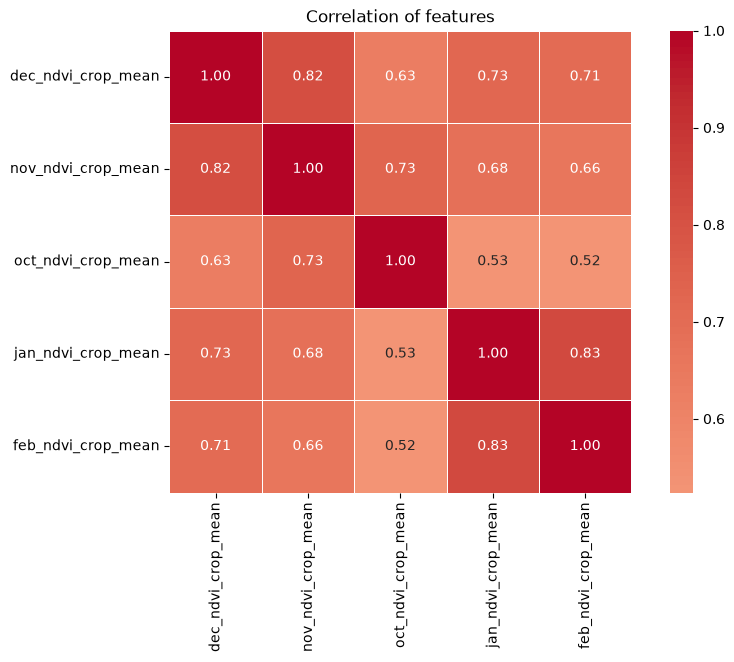

In [8]:
corr_matrix = df_selected_features[['dec_ndvi_crop_mean', 'nov_ndvi_crop_mean', 
                  'oct_ndvi_crop_mean', 'jan_ndvi_crop_mean', 
                  'feb_ndvi_crop_mean']].corr(method = 'pearson')

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_matrix,
    annot=True,  # Show numbers in each cell
    fmt=".2f",  # Format numbers to 2 decimal places
    cmap="coolwarm",  # Diverging colormap
    square=True,  # Make cells square-shaped
    linewidths=0.5,  # Add grid lines
    center=0,  # Center colormap at zero
)

plt.title("Correlation of features")
plt.show()

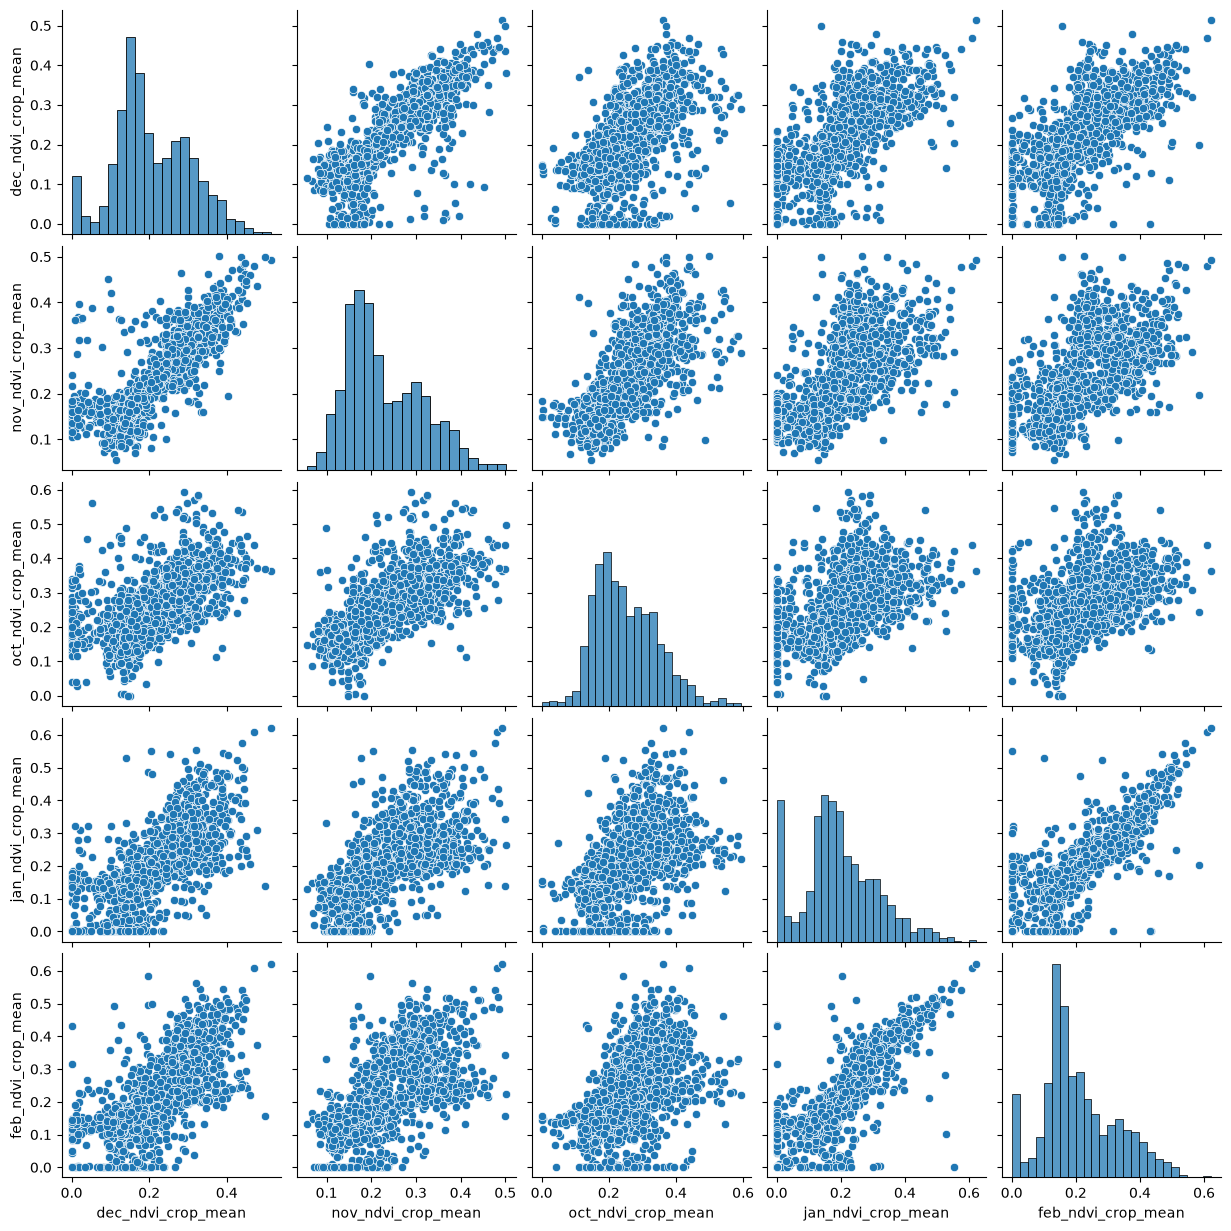

In [51]:
sns.pairplot(df_selected_features[['dec_ndvi_crop_mean', 'nov_ndvi_crop_mean', 
                  'oct_ndvi_crop_mean', 'jan_ndvi_crop_mean', 
                  'feb_ndvi_crop_mean']])

The corn growth cycle spans mostly from the end of april to mid october [1]. 
Based on our knowleage of the data and the growth cycle of corn [1] as well as the high values of correlation between january and february, and november, and december features we decided that the features characterized by the highest values of coeficients connected to the number of days in the past that the image was taken will be discarded from further analysis.

[1] A. Farbo, F. Sarvia, S. De Petris, V. Basile, E. Borgogno-Mondino, "Forecasting corn NDVI through AI-based approaches using sentinel 2 image time series", ISPRS Journal of Photogrammetry and Remote Sensing, Volume 211, 2024, https://doi.org/10.1016/j.isprsjprs.2024.04.011.


In [9]:
df_selected_features = df_selected_features.drop(
    ['dec_ndvi_crop_mean', 'dec_crop_area_km2', 'dec_ndvi_crop_per_km2','dec_area_km2', 
    'jan_ndvi_crop_mean', 'jan_crop_area_km2', 'jan_ndvi_crop_per_km2','jan_area_km2', 
    'feb_ndvi_crop_mean', 'feb_crop_area_km2', 'feb_ndvi_crop_per_km2','feb_area_km2'],
    axis=1
)

df_selected_features

,fips,county,state,year,yield_bu_acre,jan_temp_mean_k,jan_temp_std_k,jan_temp_max_k,jan_temp_min_k,jan_precip_mean_mm,...,sep_ndvi_crop_mean,sep_ndvi_crop_per_km2,oct_area_km2,oct_crop_area_km2,oct_ndvi_crop_mean,oct_ndvi_crop_per_km2,nov_area_km2,nov_crop_area_km2,nov_ndvi_crop_mean,nov_ndvi_crop_per_km2
0,47159,SMITH,TN,2020,161.5,279.569652,5.140498,293.770444,264.917222,3.969122,...,0.481492,0.014595,842.530444,24.263454,0.348030,0.010023,842.530444,17.383099,0.267318,0.005515
1,18065,HENRY,IN,2020,196.6,274.174624,4.572633,289.168333,260.628167,4.127167,...,0.342960,0.168880,1021.532661,630.260161,0.169695,0.104697,1021.532661,703.153437,0.164420,0.113176
2,36063,NIAGARA,NY,2020,153.5,272.893995,4.146960,288.756222,261.657333,2.736747,...,0.284219,0.031215,2946.327154,317.639854,0.208134,0.022439,2946.327154,344.667520,0.316738,0.037053
3,37169,STOKES,NC,2020,125.8,278.975964,4.807459,293.766000,266.504250,3.873742,...,0.468369,0.003885,1180.237614,10.178032,0.281139,0.002424,1180.237614,11.955823,0.302847,0.003068
4,31045,DAWES,NE,2020,92.9,270.921823,3.089723,281.254229,258.071813,0.332374,...,0.196644,0.055608,3622.605198,1201.001488,0.142793,0.047340,3622.605198,1732.641478,0.133290,0.063751
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1596,20003,ANDERSON,KS,2020,109.8,274.793339,4.816613,290.915250,260.536667,2.921970,...,0.398879,0.131218,1510.894719,635.040388,0.268756,0.112960,1510.894719,597.877741,0.191163,0.075645
1597,42097,NORTHUMBERLAND,PA,2020,114.3,274.098613,4.585949,291.368269,263.541846,2.386351,...,0.327571,0.060248,1235.249122,286.763422,0.276948,0.064294,1235.249122,245.072930,0.319514,0.063391
1598,26115,MONROE,MI,2020,147.4,273.267623,3.771319,285.665750,262.190812,2.980222,...,0.281744,0.106091,1758.389872,715.981658,0.207386,0.084443,1758.389872,696.193908,0.194781,0.077119
1599,29017,BOLLINGER,MO,2020,179.9,276.376275,4.185714,289.579000,264.642867,6.834308,...,0.519495,0.041577,1608.180248,142.187019,0.183892,0.016259,1608.180248,159.133871,0.226296,0.022393


In [10]:
groups = df["state"]

# get the target varaible and the features separated
y = df[target_label]
X = df.drop(columns=[*non_numeric_labels, target_label])

y_selected_features = df_selected_features[target_label]
X_selected_features = df_selected_features.drop(columns=[*non_numeric_labels, target_label])

In [88]:
from sklearn.feature_selection import mutual_info_regression

mi = mutual_info_regression(X, y)
print(len(mi))

312


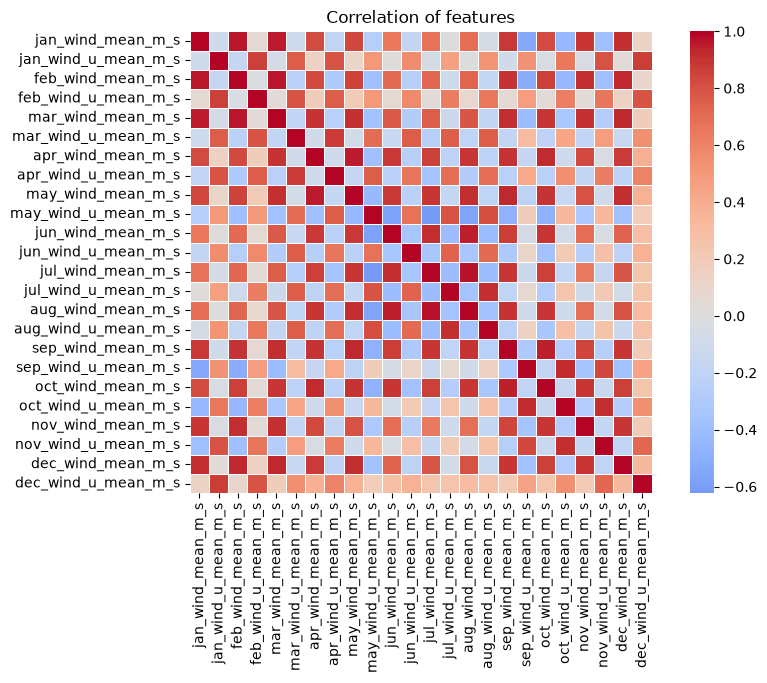

In [115]:
col_list = [col for col in df_selected_features.columns if col.endswith('_wind_u_mean_m_s') or col.endswith('_wind_mean_m_s')]


corr_matrix = df_selected_features[col_list].corr(method = "pearson")

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_matrix,
    # annot=True, 
    fmt=".2f",  
    cmap="coolwarm",  
    square=True, 
    linewidths=0.5,  
    center=0, 
)

plt.title("Correlation of features")
plt.show()

We decided to group ur dataset by state

# **Model selection**

In [87]:
import time

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

RANDOM_STATE = 51

Y_BINS = 5
OUTER_SPLITS = 5
INNER_SPLITS = 4


def evaluate_model(model, X, y, groups, outer_cv, inner_cv):
    rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_bin, groups)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        estimator, grid = model
        inner_splits = list(inner_cv.split(X_train, y_bin[train_idx], groups.iloc[train_idx]))

        scoring = "neg_root_mean_squared_error"
        # clone(...) ensures that each model is fit once per set of parameters (i.e. no re-fitting)
        # GridSearchCV returns an instance of a fitted estimator.
        search = GridSearchCV(clone(estimator), grid, cv=inner_splits, scoring=scoring, n_jobs=-1)

        t0 = time.perf_counter()
        final_model = search.fit(X_train, y_train)
        fit_time = time.perf_counter() - t0

        t0 = time.perf_counter()
        pred = final_model.predict(X_test)
        predict_time = time.perf_counter() - t0

        rows.append({
            "fold": fold,
            "best_params": final_model.best_params_,
            "mae": mean_absolute_error(y_test, pred),
            "rmse": root_mean_squared_error(y_test, pred),
            "r2": r2_score(y_test, pred),
            "fit_time": fit_time,
            "predict_time": predict_time,
        })

    return pd.DataFrame(rows)


y_bin = pd.qcut(y, Y_BINS, labels=False)
outer_cv = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# TODO: the only assertion that we're making is that if you use this grid search approach with these params you can expect a generalisation error in this range.

In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline

pd.set_option('display.max_colwidth', None)

NUM_FEATURES = len(X.columns)
NUM_FEATURES_AFTER_SELECTION = len(X_selected_features.columns)

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class SesonalFeatureSelector(BaseEstimator, TransformerMixin):
    """This custom feature selector depending on the setting 
    either keeps all of the features for the entire year or 
    selects features that are connected to the growing seson 
    of corn (april to october).

    Parameters
    ==============
    time_period: str or None
    the time period of the features of interest 
     - for the growing season features the "growing_season" 
    option should be selected. 
     - any other str value or None are equal to all year 
     features for corn.

    fit(X, y=None)
    =================
    Check the columns of X.

    transform(X)
    =================
    Reduce X to the selected feature columns.


    """
    def __init__(self, time_period=None):
        self.time_period = time_period


    def fit(self, X, y=None):
        self.columns_ = X.columns
        return self

    def transform(self, X):
        if self.time_period == "growing_season":
            months = ("jan", "feb", "mar", "nov", "dec")
            col_list = [col for col in self.columns_ if col.startswith(months)]
            X_dropped = X.drop(columns=col_list)
            return X_dropped
        else:
            return X

class IncludeIrigationData(BaseEstimator, TransformerMixin):

    def __init__(self, include=True):
        self.include = include


    def fit(self, X, y=None):
        
        return self

    def transform(self, X):
        if self.include == True:
            return X
        else:
            return X.drop("percentage_irigated")
    

## **Dummy regressor**




In [ ]:
dummy = (
            make_pipeline(SesonalFeatureSelector(), DummyRegressor()),
            {
                "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
                "dummyregressor__strategy": ["mean", "median"]
            },
        )

result_dummy = evaluate_model(dummy, X, y, groups, outer_cv, inner_cv)
display(result_dummy)

,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",29.746368,35.807853,-0.000090,0.517416,0.000382
1,1,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",29.984766,38.856411,-0.000920,0.491088,0.000347
2,2,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",28.515344,34.393317,-0.002023,0.645155,0.000452
3,3,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",29.108501,35.823895,-0.002067,0.523874,0.000273
4,4,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",28.271141,34.961919,-0.000692,0.557955,0.000709


In [79]:
result_selected_dummy = evaluate_model(dummy, X_selected_features, y_selected_features, groups, outer_cv, inner_cv)
display(result_selected_dummy)

,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",29.746368,35.807853,-0.000090,21.577598,0.001854
1,1,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",29.984766,38.856411,-0.000920,0.840892,0.000532
2,2,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",28.515344,34.393317,-0.002023,0.838771,0.000499
3,3,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",29.108501,35.823895,-0.002067,0.733055,0.000327
4,4,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__seson': 'all_year'}",28.271141,34.961919,-0.000692,0.606649,0.000463


## **Elastic Net regression**

Elastic Net regression model is a Linear regression model with included additional regularization to minimalize model complexity and avoid overfitting. Elastic Net includes both the L1-norm and L2-norm, combining the feature selection capabilities of LASSO regression and the shared weights of the Ridge regression algorithm. This algorithm allowes for flexibilility with choosing thich regulrization should be more penalized with its hyperparameters.

#### Advantages:
- flexibilility with regularization techniques 
- possible feature selection to shink model complexity
- 

#### Disadvantages:
- 
- 
- 

#### Hyperparameters to tune:
- **`alpha`**: the regulariztion parameter which controls the amount of regularization on the model (can go from 0 to +∞, where 0 is no regularization so a standard linear regression and +∞ sets the beta parameters to 0 so maximal regularization possible)
- **`l1_ratio`**: the importance of the L1 penalty or the mixinig parameter
- **`tol`**: ??? the learning rate, (is that a hyperparamenter to be tuned with corss-validation??????) --> is it the learning reat


In [89]:
elastic_net = (
        make_pipeline(SesonalFeatureSelector(), StandardScaler(), ElasticNet(random_state = RANDOM_STATE)),
        {
            "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
            "elasticnet__alpha": [0, 0.5, 1, 2, 5, 10, 50, 100, 500, 1000, 5000],
            "elasticnet__l1_ratio": [0.01, 0.1, 0.25, 0.35, 0.5, 0.75, 0.9, 0.95, 1]
        },
)

result_elastic_net = evaluate_model(elastic_net, X, y, groups, outer_cv, inner_cv)
display(result_elastic_net)

c:\Users\nikak\Desktop\szkola\ML_Cropet\CropNet\.pixi\envs\default\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,"{'elasticnet__alpha': 0.5, 'elasticnet__l1_ratio': 1, 'sesonalfeatureselector__time_period': 'growing_season'}",22.253244,28.916674,0.347802,46.855148,0.027117
1,1,"{'elasticnet__alpha': 1, 'elasticnet__l1_ratio': 0.95, 'sesonalfeatureselector__time_period': 'all_year'}",24.771609,31.809592,0.329205,56.386937,0.026912
2,2,"{'elasticnet__alpha': 0.5, 'elasticnet__l1_ratio': 0.9, 'sesonalfeatureselector__time_period': 'growing_season'}",16.453308,20.549061,0.642305,59.349701,0.019364
3,3,"{'elasticnet__alpha': 1, 'elasticnet__l1_ratio': 0.9, 'sesonalfeatureselector__time_period': 'growing_season'}",18.587899,24.280257,0.539682,57.462038,0.021863
4,4,"{'elasticnet__alpha': 2, 'elasticnet__l1_ratio': 1, 'sesonalfeatureselector__time_period': 'growing_season'}",21.549334,28.162775,0.350677,1936.993092,0.024469


With feature selection

In [78]:
result_selected_elastic_net = evaluate_model(elastic_net, X_selected_features, y, groups, outer_cv, inner_cv)
display(result_selected_elastic_net)

Num_feartures 168
Num_feartures 168
Original features
Original features
Num_feartures 168
Num_feartures 168
Num_feartures 168
Num_feartures 168
Num_feartures 168
Num_feartures 168


,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,"{'elasticnet__alpha': 0.5, 'elasticnet__l1_ratio': 1, 'sesonalfeatureselector__seson': 'sesonal'}",22.075779,28.708013,0.357181,29.194613,0.011583
1,1,"{'elasticnet__alpha': 1, 'elasticnet__l1_ratio': 0.95, 'sesonalfeatureselector__seson': 'all_year'}",24.551138,31.384086,0.347031,27.368401,0.008428
2,2,"{'elasticnet__alpha': 0.5, 'elasticnet__l1_ratio': 0.9, 'sesonalfeatureselector__seson': 'sesonal'}",16.462881,20.558577,0.641973,26.398426,0.011543
3,3,"{'elasticnet__alpha': 1, 'elasticnet__l1_ratio': 0.9, 'sesonalfeatureselector__seson': 'sesonal'}",18.594630,24.290438,0.539296,31.007862,0.009358
4,4,"{'elasticnet__alpha': 2, 'elasticnet__l1_ratio': 1, 'sesonalfeatureselector__seson': 'sesonal'}",21.549334,28.162775,0.350677,27.552192,0.008036


In [88]:
# linear regression

from sklearn.linear_model import LinearRegression

linear_reg = (
        make_pipeline(SesonalFeatureSelector(), StandardScaler(), LinearRegression()),
        {
            "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
        },
)

result_lr = evaluate_model(linear_reg, X, y, groups, outer_cv, inner_cv)
display(result_lr)

,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,{'sesonalfeatureselector__time_period': 'growing_season'},30.650716,78.780941,-3.840888,0.413665,0.011265
1,1,{'sesonalfeatureselector__time_period': 'growing_season'},173.318642,1159.596942,-890.431571,0.318400,0.009924
2,2,{'sesonalfeatureselector__time_period': 'growing_season'},22.660485,28.527874,0.310605,0.325171,0.008193
3,3,{'sesonalfeatureselector__time_period': 'growing_season'},21.640806,27.281365,0.418857,0.309366,0.008185
4,4,{'sesonalfeatureselector__time_period': 'growing_season'},26.772723,34.882600,0.003843,0.343457,0.011646


In [85]:
result_lr = evaluate_model(linear_reg, X_selected_features, y_selected_features, groups, outer_cv, inner_cv)
display(result_lr)

,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,{'sesonalfeatureselector__time_period': 'growing_season'},24.588444,32.626990,0.169697,0.367522,0.010270
1,1,{'sesonalfeatureselector__time_period': 'growing_season'},24.812753,33.856464,0.240099,0.291133,0.009310
2,2,{'sesonalfeatureselector__time_period': 'growing_season'},22.541910,28.378157,0.317822,0.286813,0.007419
3,3,{'sesonalfeatureselector__time_period': 'growing_season'},21.963017,27.575332,0.406265,0.264896,0.009733
4,4,{'sesonalfeatureselector__time_period': 'all_year'},22.363545,31.417269,0.191934,0.308266,0.010547


## **Random Forest**

The Random Forest is ensamble estimator which uses averaging of multiple Decision Tree model predictions on bootstrap samples of the original dataset to obtain the final target prediction. The use of multiple decision trees is supposed to minimalize the varaince of the model, by aggregating the results of all of the trees, and so minimalize the risk of overfitting. Additionally,  for each split in the Decision Trees Random Forest uses a random subset of features to additionally lower the corelation between the samples. 

#### Advantages:
- can be used for both regression and classification problems
- less prone to overfitting then Decision Tree models
- good at handeling missing values and outliers

#### Disadvantages:
- multiple hyperparameters to tune
- time consuming training 
- 

#### Hyperparameters to tune:
- **`n_estimators`**: number of decision trees in the forest (the bigger the more stable the prediction)
- **`max_features`**: procentage of features used for each split (if 1 then all of the features are used)
- **`max_samples`**: number of data points in the bootstrap samples (if 1 the bootstrap samples are of the same size as the original dataset)
- **`min_samples_split`**: minimal numbr of samples per node that can be still split 

In [148]:
print(round(NUM_FEATURES*0.333))
print(round(NUM_FEATURES/3))

104
104


In [ ]:
def set_max_features(X, model):
    max_features = round(len(X.columns)/3)
    model.set_params(randomforestregressor__max_features = max_features)

In [ ]:
rf = (
            make_pipeline(RandomForestRegressor(random_state=0, n_jobs=-1, n_estimators = 500, bootstrap = True)),
            {
                "randomforestregressor__max_features": [0.33, 0.5, 0.75, 0.9, 1.0],
                "randomforestregressor__max_samples": [0.75, 0.9, 1.0],
                "randomforestregressor__min_samples_split": [2, 5, 10]
            },
        )

result_rf = evaluate_model(rf, X_arr, y_arr, groups_arr, outer_cv, inner_cv)
display(result_rf)

With feature selection

In [ ]:
result_rf = evaluate_model(rf, X_selected_features_arr, y_arr, groups_arr, outer_cv, inner_cv)
display(result_rf)

# NOT NEEDED ONLY TO CHECK 
- generic univariate feature selector


In [16]:
# take out the numerical feature values from the dataset
from sklearn.compose import make_column_selector
num_col_select = make_column_selector(dtype_include=[int, float])
num_col = num_col_select(x)
x_num = x[num_col].set_index('fips', drop = True)
print(x_num.columns)

Index(['jan_temp_mean_k', 'jan_temp_std_k', 'jan_temp_max_k', 'jan_temp_min_k',
       'jan_precip_mean_mm', 'jan_precip_std_mm', 'jan_rh_mean_pct',
       'jan_rh_std_pct', 'jan_gust_mean_m_s', 'jan_gust_std_m_s',
       ...
       'sep_ndvi_crop_mean', 'sep_ndvi_crop_per_km2', 'oct_area_km2',
       'oct_crop_area_km2', 'oct_ndvi_crop_mean', 'oct_ndvi_crop_per_km2',
       'nov_area_km2', 'nov_crop_area_km2', 'nov_ndvi_crop_mean',
       'nov_ndvi_crop_per_km2'],
      dtype='str', length=276)


In [123]:
from sklearn.feature_selection import GenericUnivariateSelect, f_regression
transformer = GenericUnivariateSelect(f_regression, mode= 'percentile', param = 10)
x_select = transformer.fit_transform(X, y)
print(transformer.get_feature_names_out())

['jan_rh_mean_pct' 'jan_gust_std_m_s' 'jan_srad_mean_w_m2'
 'jan_vpd_mean_kpa' 'feb_rh_mean_pct' 'feb_rh_std_pct' 'feb_vpd_mean_kpa'
 'feb_vpd_std_kpa' 'mar_rh_mean_pct' 'mar_gust_std_m_s'
 'mar_srad_mean_w_m2' 'mar_vpd_mean_kpa' 'jun_rh_std_pct' 'jul_temp_max_k'
 'jul_wind_v_mean_m_s' 'sep_wind_v_mean_m_s' 'dec_rh_mean_pct'
 'dec_rh_std_pct' 'dec_vpd_mean_kpa' 'dec_vpd_std_kpa'
 'apr_ndvi_crop_per_km2' 'may_ndvi_crop_mean' 'may_ndvi_crop_per_km2'
 'jun_ndvi_crop_per_km2' 'jul_ndvi_crop_mean' 'jul_ndvi_crop_per_km2'
 'aug_ndvi_crop_mean' 'aug_ndvi_crop_per_km2' 'sep_ndvi_crop_per_km2'
 'oct_ndvi_crop_per_km2' 'nov_ndvi_crop_mean' 'nov_ndvi_crop_per_km2']


compare the test 

In [124]:
result_select_elastic_net = evaluate_model(elastic_net, x_select, y_arr, groups_arr, outer_cv, inner_cv)
display(result_select_elastic_net)

,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,"{'elasticnet__alpha': 0.5, 'elasticnet__l1_ratio': 0.35}",27.017731,32.167209,0.192933,0.623568,0.000625
1,1,"{'elasticnet__alpha': 0.5, 'elasticnet__l1_ratio': 0.5}",24.931464,32.946146,0.280413,0.647431,0.000708
2,2,"{'elasticnet__alpha': 5, 'elasticnet__l1_ratio': 1}",17.787823,23.250929,0.542058,0.639038,0.000596
3,3,"{'elasticnet__alpha': 2, 'elasticnet__l1_ratio': 0.25}",21.943190,29.435803,0.323446,0.602719,0.000693
4,4,"{'elasticnet__alpha': 5, 'elasticnet__l1_ratio': 1}",22.102143,29.850061,0.270542,0.614254,0.000636
